# Bab 6 – Advanced Logistic Regression

## Ringkasan Bab
Logistic regression adalah model klasifikasi linear yang memprediksi **probabilitas** suatu kelas. Bab ini membahas dasarnya,
cara memperluasnya ke **klasifikasi multikelas** (One-vs-Rest dan multinomial), **regularisasi** (L1, L2, Elastic Net),
konsep **klasifikasi multilabel**, serta **metrik evaluasi** yang tepat. Bab ditutup dengan tiga latihan praktik.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_wine, make_multilabel_classification
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                             log_loss, RocCurveDisplay, hamming_loss, f1_score, accuracy_score, PrecisionRecallDisplay)
import warnings; warnings.filterwarnings("ignore")

## 1. Gambaran Umum Logistic Regression
Model menghitung skor linear z = w·x + b, lalu mengubahnya menjadi probabilitas dengan fungsi **sigmoid**:
P(y=1|x) = 1 / (1 + e^(−z)). Parameter dilatih dengan meminimalkan **log-loss** (cross-entropy):
−[y·log(p) + (1−y)·log(1−p)]. Koefisien dapat ditafsirkan sebagai perubahan **log-odds** untuk kenaikan satu satuan fitur,
dan e^w adalah *odds ratio*.

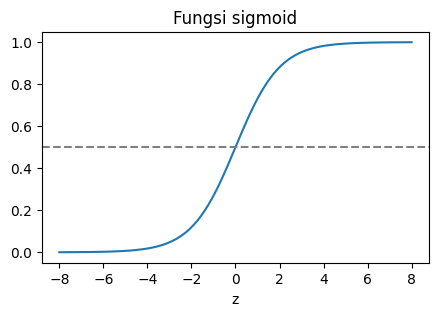

Akurasi uji: 0.986
Probabilitas 3 data pertama:
 [[0.031 0.969]
 [1.    0.   ]
 [0.441 0.559]]
Odds ratio 3 fitur teratas: [0.593 0.595 0.617]


In [2]:
z = np.linspace(-8, 8, 200)
plt.figure(figsize=(5, 3)); plt.plot(z, 1/(1+np.exp(-z))); plt.axhline(.5, ls="--", c="gray")
plt.title("Fungsi sigmoid"); plt.xlabel("z"); plt.show()

Xb, yb = load_breast_cancer(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(Xb, yb, test_size=.25, stratify=yb, random_state=42)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
print("Akurasi uji:", round(lr.score(Xte, yte), 3))
print("Probabilitas 3 data pertama:\n", lr.predict_proba(Xte[:3]).round(3))
print("Odds ratio 3 fitur teratas:", np.exp(lr[-1].coef_[0])[:3].round(3))

## 2. Teknik Klasifikasi Multikelas
* **One-vs-Rest (OvR):** melatih satu model biner per kelas ("kelas ini vs sisanya"), lalu memilih kelas dengan skor tertinggi.
* **Multinomial (softmax):** satu model yang menghasilkan probabilitas semua kelas sekaligus, dengan P(k|x) = e^(z_k) / Σ e^(z_j).
  Ini perilaku default `LogisticRegression` pada solver seperti `lbfgs`.
* **One-vs-One (OvO):** satu model untuk setiap pasangan kelas (dipakai SVM, lihat Bab 7).

In [3]:
Xw, yw = load_wine(return_X_y=True)
Xwtr, Xwte, ywtr, ywte = train_test_split(Xw, yw, test_size=.3, stratify=yw, random_state=0)
multi = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xwtr, ywtr)
ovr = make_pipeline(StandardScaler(), OneVsRestClassifier(LogisticRegression(max_iter=1000))).fit(Xwtr, ywtr)
print("Multinomial akurasi:", round(multi.score(Xwte, ywte), 3), "| OvR akurasi:", round(ovr.score(Xwte, ywte), 3))
print("Bentuk coef_ multinomial:", multi[-1].coef_.shape, "(satu baris koefisien per kelas)")
print("Jumlah probabilitas tiap baris:", multi.predict_proba(Xwte[:3]).sum(1))

Multinomial akurasi: 1.0 | OvR akurasi: 1.0
Bentuk coef_ multinomial: (3, 13) (satu baris koefisien per kelas)
Jumlah probabilitas tiap baris: [1. 1. 1.]


## 3. Teknik Regularisasi
Parameter `C` adalah **kebalikan** kekuatan regularisasi (C kecil = regularisasi kuat), berbeda dengan `alpha` di Ridge/Lasso.
* **L2 (default):** menyusutkan semua koefisien.
* **L1:** membuat sebagian koefisien tepat nol, sehingga ada seleksi fitur. Butuh solver `liblinear` atau `saga`.
* **Elastic Net:** campuran L1 dan L2, hanya dengan solver `saga`.

In [4]:
rows = []
for name, kw in [("L2", dict(penalty="l2")), ("L1", dict(penalty="l1", solver="liblinear")),
                 ("ElasticNet", dict(penalty="elasticnet", solver="saga", l1_ratio=.5))]:
    for C in [0.01, 0.1, 1, 10]:
        m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000, **kw)).fit(Xtr, ytr)
        rows.append({"penalti": name, "C": C, "akurasi uji": round(m.score(Xte, yte), 3),
                     "koefisien non-nol": int((m[-1].coef_ != 0).sum())})
pd.DataFrame(rows).pivot(index="C", columns="penalti", values=["akurasi uji", "koefisien non-nol"])

akurasi uji               koefisien non-nol            
penalti  ElasticNet     L1     L2        ElasticNet    L1    L2
C                                                              
0.01          0.930  0.909  0.937              12.0   4.0  30.0
0.10          0.972  0.972  0.979              18.0   7.0  30.0
1.00          0.986  0.993  0.986              25.0  16.0  30.0
10.00         0.972  0.958  0.972              28.0  22.0  30.0

## 4. Konsep Klasifikasi Multilabel
Pada **multikelas**, setiap data punya *tepat satu* label dari beberapa kelas. Pada **multilabel**, setiap data bisa punya
*beberapa label sekaligus* (contoh: satu artikel bertopik "politik" dan "ekonomi"). Targetnya berupa matriks biner
(sampel × label). Pendekatan umum: `OneVsRestClassifier` yang melatih satu model biner per label.

In [5]:
Xm, Ym = make_multilabel_classification(n_samples=600, n_features=20, n_classes=5, n_labels=2, random_state=0)
Xm_tr, Xm_te, Ym_tr, Ym_te = train_test_split(Xm, Ym, test_size=.25, random_state=0)
ml = OneVsRestClassifier(LogisticRegression(max_iter=1000)).fit(Xm_tr, Ym_tr)
P = ml.predict(Xm_te)
print("Contoh label asli :", Ym_te[0], "| prediksi:", P[0])
print("Hamming loss      :", round(hamming_loss(Ym_te, P), 3), "(makin kecil makin baik)")
print("F1 micro / macro  :", round(f1_score(Ym_te, P, average='micro'), 3), "/", round(f1_score(Ym_te, P, average='macro'), 3))
print("Exact match ratio :", round(accuracy_score(Ym_te, P), 3), "(semua label harus benar)")

Contoh label asli : [0 1 1 0 1] | prediksi: [0 1 1 0 1]
Hamming loss      : 0.207 (makin kecil makin baik)
F1 micro / macro  : 0.695 / 0.69
Exact match ratio : 0.373 (semua label harus benar)


## 5. Metrik Evaluasi Model
| Metrik | Kegunaan |
|---|---|
| Accuracy | proporsi prediksi benar; menyesatkan bila kelas tidak seimbang |
| Precision | dari yang diprediksi positif, berapa yang benar-benar positif |
| Recall | dari yang sebenarnya positif, berapa yang berhasil terdeteksi |
| F1 | rata-rata harmonik precision dan recall |
| ROC-AUC | kemampuan memisahkan kelas pada semua threshold |
| Log-loss | kualitas probabilitas yang dihasilkan (makin kecil makin baik) |

Untuk multikelas, rata-rata bisa **macro** (setiap kelas bobotnya sama) atau **weighted** (dibobot jumlah data).

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        53
      benign       0.99      0.99      0.99        90

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143

ROC-AUC: 0.9977 | log-loss: 0.0679


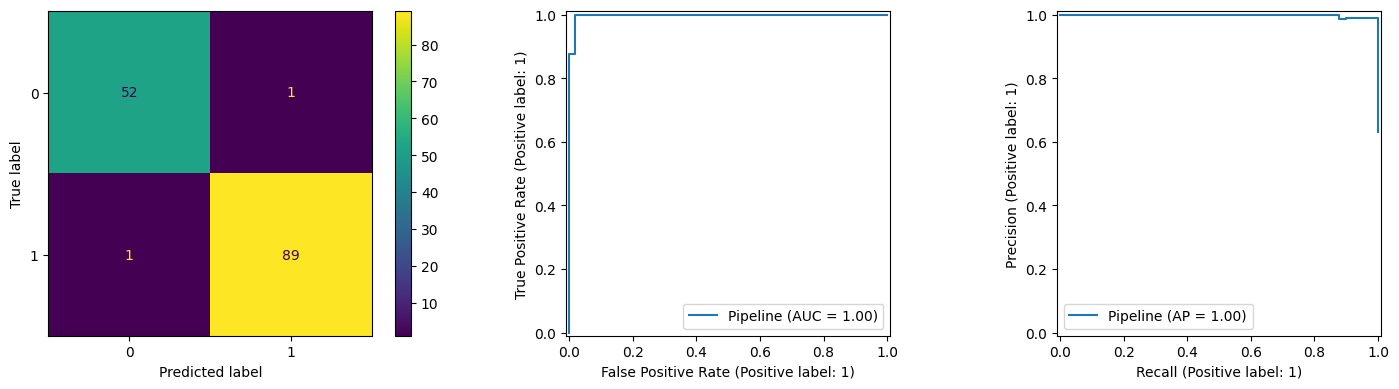

ROC-AUC multikelas (OvR, macro): 1.0


In [6]:
pred = lr.predict(Xte)
print(classification_report(yte, pred, target_names=load_breast_cancer().target_names))
print("ROC-AUC:", round(roc_auc_score(yte, lr.predict_proba(Xte)[:, 1]), 4), "| log-loss:", round(log_loss(yte, lr.predict_proba(Xte)), 4))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_predictions(yte, pred, ax=ax[0]); RocCurveDisplay.from_estimator(lr, Xte, yte, ax=ax[1])
PrecisionRecallDisplay.from_estimator(lr, Xte, yte, ax=ax[2]); plt.tight_layout(); plt.show()
print("ROC-AUC multikelas (OvR, macro):", round(roc_auc_score(ywte, multi.predict_proba(Xwte), multi_class="ovr"), 4))

## 6. Latihan Praktik

### Latihan 1 – Logistic Regression Teregularisasi
Cari nilai `C` terbaik untuk penalti L1 dan L2 dengan grid search.

In [7]:
gs = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(solver="liblinear", max_iter=2000)),
                  {"logisticregression__penalty": ["l1", "l2"], "logisticregression__C": np.logspace(-2, 2, 9)},
                  cv=5, scoring="roc_auc").fit(Xtr, ytr)
print("Terbaik:", gs.best_params_, "| AUC CV:", round(gs.best_score_, 4), "| AUC uji:", round(roc_auc_score(yte, gs.predict_proba(Xte)[:, 1]), 4))

Terbaik: {'logisticregression__C': np.float64(0.1), 'logisticregression__penalty': 'l2'} | AUC CV: 0.9951 | AUC uji: 0.9971


### Latihan 2 – Evaluasi Klasifikasi Multikelas
Tampilkan confusion matrix dan laporan per kelas untuk dataset wine.

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        18
           1       1.00      1.00      1.00        21
           2       1.00      1.00      1.00        15

    accuracy                           1.00        54
   macro avg       1.00      1.00      1.00        54
weighted avg       1.00      1.00      1.00        54



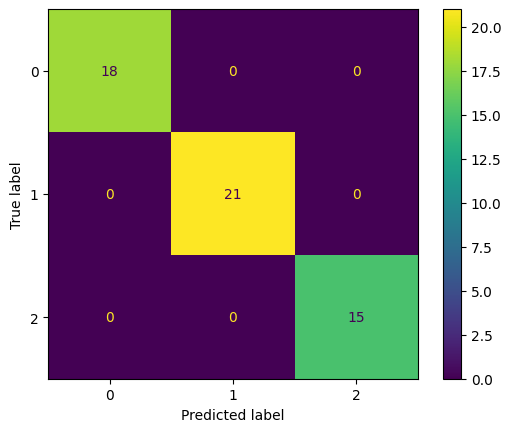

In [8]:
pw = multi.predict(Xwte)
print(classification_report(ywte, pw))
ConfusionMatrixDisplay.from_predictions(ywte, pw); plt.show()

### Latihan 3 – Visualisasi Jalur Regularisasi
Amati bagaimana koefisien L1 menyusut menjadi nol ketika `C` mengecil.

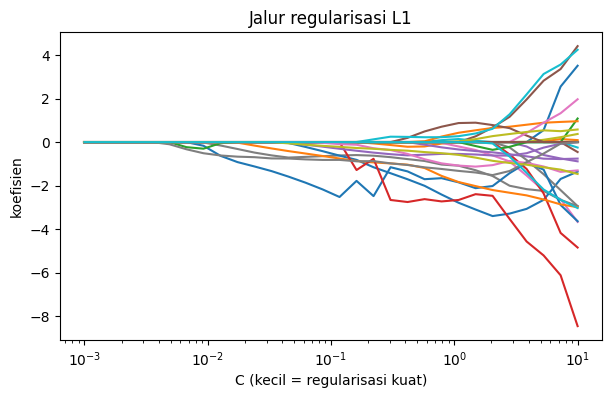

In [9]:
Cs = np.logspace(-3, 1, 30); Xs = StandardScaler().fit_transform(Xb)
coefs = [LogisticRegression(penalty="l1", solver="liblinear", C=c).fit(Xs, yb).coef_[0] for c in Cs]
plt.figure(figsize=(7, 4)); plt.plot(Cs, coefs); plt.xscale("log"); plt.xlabel("C (kecil = regularisasi kuat)")
plt.ylabel("koefisien"); plt.title("Jalur regularisasi L1"); plt.show()

**Kesimpulan:** logistic regression memberi probabilitas yang bisa ditafsirkan. Pilih penalti sesuai kebutuhan (L2 untuk stabilitas,
L1 untuk seleksi fitur), dan jangan hanya mengandalkan akurasi saat kelas tidak seimbang.